In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import yfinance as yf
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

def backtest_crossover_strategy(asset1, predictors, days=700, min_history=90, ma_window=200):
    """
    Backtest a crossover strategy using linear regression.

    Parameters:
    - asset1 (str): Ticker of the target asset to predict (e.g., 'QQQ').
    - predictors (list): List of ticker strings for predictor assets (e.g., ['SPY', 'GC=F']).
    - days (int): Number of days of historical data (default: 700).
    - min_history (int): Minimum days to fit initial model (default: 90).
    - ma_window (int): Window for moving average of predicted price (default: 200).

    Returns:
    - dict: Performance metrics (total returns, Sharpe ratios).
    """
    # Download historical data from Yahoo Finance
    end_date = datetime.now()
    start_date = end_date - timedelta(days=days + ma_window)  # Include extra days for MA
    tickers = [asset1] + predictors
    data = yf.download(tickers, start=start_date, end=end_date)['Close']
    data = data.fillna(method='ffill')
    print("Missing values after ffill:\n", data.isna().sum())
    data = data.dropna()

    # Check if DataFrame is empty after alignment
    if data.empty:
        print("Error: No overlapping data available after alignment.")
        return {}

    # Initialize lists for out-of-sample predictions
    predictions = []
    dates = data.index[min_history:]

    for i in range(min_history, len(data)):
        # Training data up to i-1
        train_data = data.iloc[:i]
        X_train = train_data[predictors].values
        y_train = train_data[asset1].values

        # Fit model
        model = LinearRegression()
        model.fit(X_train, y_train)

        # Predict on day i
        X_test = data[predictors].iloc[[i]].values
        pred = model.predict(X_test)[0]

        predictions.append(pred)

    # Create results DataFrame
    results = pd.DataFrame({
        f'Actual_{asset1}': data[asset1].iloc[min_history:],
        f'Predicted_{asset1}': predictions
    }, index=dates)

    # Calculate 200-day moving average of predicted price
    results[f'Predicted_{asset1}_MA200'] = results[f'Predicted_{asset1}'].rolling(window=ma_window).mean()

    # Drop rows where MA200 is NaN
    results = results.dropna()

    # Detect crossovers with predicted MA200
    results['Cross_Up'] = (results[f'Predicted_{asset1}'] > results[f'Predicted_{asset1}_MA200']) & (results[f'Predicted_{asset1}'].shift(1) <= results[f'Predicted_{asset1}_MA200'].shift(1))
    results['Cross_Down'] = (results[f'Predicted_{asset1}'] < results[f'Predicted_{asset1}_MA200']) & (results[f'Predicted_{asset1}'].shift(1) >= results[f'Predicted_{asset1}_MA200'].shift(1))

    # Generate signals: 1 for long (prediction crosses over predicted MA200), -1 for short (crosses under)
    results['Signal'] = 0
    results.loc[results['Cross_Up'], 'Signal'] = 1
    results.loc[results['Cross_Down'], 'Signal'] = -1

    # Position: hold until opposite signal
    results['Position'] = results['Signal'].replace(0, np.nan).ffill().fillna(0)

    # Compute daily returns
    asset_returns = data[asset1].pct_change()

    # Strategy returns: position at t * return from t to t+1
    strategy_returns = results['Position'].shift(1) * asset_returns.loc[results.index]
    strategy_returns = strategy_returns.dropna()

    # Cumulative returns
    cum_asset = (1 + asset_returns.loc[strategy_returns.index]).cumprod() - 1
    cum_strategy = (1 + strategy_returns).cumprod() - 1

    # Performance metrics
    metrics = {
        'backtest_period_start': strategy_returns.index[0].date(),
        'backtest_period_end': strategy_returns.index[-1].date(),
        'total_asset_return': cum_asset.iloc[-1],
        'total_strategy_return': cum_strategy.iloc[-1],
        'strategy_sharpe': (strategy_returns.mean() / strategy_returns.std()) * np.sqrt(252) if strategy_returns.std() != 0 else np.nan,
        'asset_sharpe': (asset_returns.loc[strategy_returns.index].mean() / asset_returns.loc[strategy_returns.index].std()) * np.sqrt(252) if asset_returns.loc[strategy_returns.index].std() != 0 else np.nan
    }

    # Print performance metrics
    print(f"Backtest Period: {metrics['backtest_period_start']} to {metrics['backtest_period_end']}")
    print(f"Total {asset1} Return: {metrics['total_asset_return']:.2%}")
    print(f"Total Strategy Return: {metrics['total_strategy_return']:.2%}")
    print(f"Strategy Sharpe Ratio: {metrics['strategy_sharpe']:.2f}" if not np.isnan(metrics['strategy_sharpe']) else "Strategy Sharpe Ratio: N/A")
    print(f"{asset1} Sharpe Ratio: {metrics['asset_sharpe']:.2f}" if not np.isnan(metrics['asset_sharpe']) else f"{asset1} Sharpe Ratio: N/A")

    # Plot cumulative returns
    plt.figure(figsize=(12, 6))
    plt.plot(cum_asset, label=f'Buy & Hold {asset1}', color='#1E88E5', linewidth=2)
    plt.plot(cum_strategy, label='Strategy', color='#D81B60', linewidth=2)
    plt.title(f'Cumulative Returns: Strategy vs Buy & Hold {asset1}', fontsize=14)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Cumulative Return', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plot actual, predicted, and predicted MA200 with cross points
    plt.figure(figsize=(12, 6))
    plt.plot(results.index, results[f'Actual_{asset1}'], label=f'Actual {asset1}', color='#1E88E5', linewidth=2)
    plt.plot(results.index, results[f'Predicted_{asset1}'], label=f'Predicted {asset1}', color='#D81B60', linewidth=2, linestyle='--')
    plt.plot(results.index, results[f'Predicted_{asset1}_MA200'], label=f'Predicted {asset1} MA200', color='#FFA000', linewidth=2, linestyle='-.')
    plt.scatter(results[results['Cross_Up']].index, results[results['Cross_Up']][f'Predicted_{asset1}_MA200'], color='green', marker='^', label='Long Signal', s=100)
    plt.scatter(results[results['Cross_Down']].index, results[results['Cross_Down']][f'Predicted_{asset1}_MA200'], color='red', marker='v', label='Short Signal', s=100)
    plt.title(f'Actual {asset1}, Predicted {asset1}, and Predicted MA200 with Crossover Signals', fontsize=14)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Price (USD)', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return metrics


/tmp/ipython-input-3043843808.py:26: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  3 of 3 completed
/tmp/ipython-input-3043843808.py:27: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method='ffill')


Missing values after ffill:
 Ticker
BTC-USD    0
GC=F       0
SPY        0
dtype: int64
Backtest Period: 2020-06-14 to 2025-09-06
Total BTC-USD Return: 1072.78%
Total Strategy Return: -76.08%
Strategy Sharpe Ratio: -0.30
BTC-USD Sharpe Ratio: 0.91


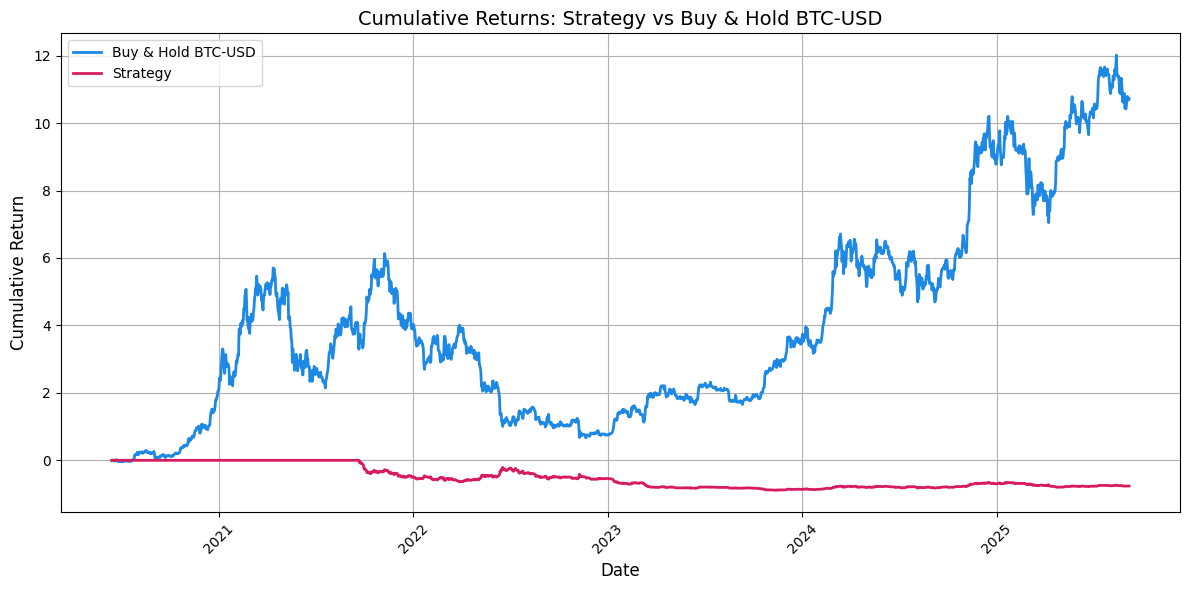

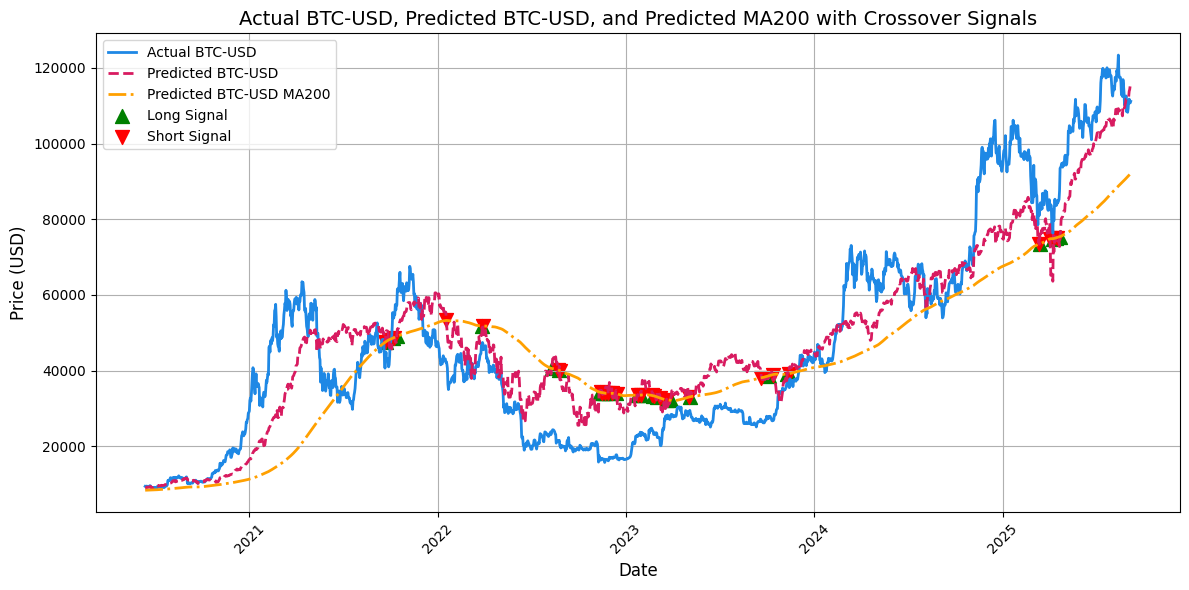

In [ ]:

# Example usage
ticker = 'BTC-USD'
predictors = ['SPY','GC=F']
days = 2000
if __name__ == "__main__":
    metrics = backtest_crossover_strategy(ticker, predictors, days=days)